<a href="https://colab.research.google.com/github/yuma1228/Software-Science-Experiment-B/blob/main/ex1_evolutionary_policy_optimization.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 課題内容

ここでは，`1_policy_optimization_introduction.ipynb`で学んだ内容を発展させ，「より優れた方策を獲得する方法」を検討し，実験的に評価しましょう．

そのために，次のようなステップで検討していきます．
1. 「より優れた方策を獲得できる方法」という曖昧な目的を明確にしましょう．
2. 明確になった目的を評価するための方法を検討しましょう．
3. 各々方法を検討し，実験を実施し，比較しましょう．

# 0. 準備

`1_policy_optimization_introduction.ipynb`から必要なコードをコピーしてきます．

## 0.1 インストール＆インポート

In [3]:
# 必要なパッケージのインストール
!apt update
!pip install swig
!apt install xvfb
!pip install pyvirtualdisplay
!pip install gymnasium[box2d]

Get:1 https://cloud.r-project.org/bin/linux/ubuntu noble-cran40/ InRelease [3,631 B]
Get:2 https://cli.github.com/packages stable InRelease [3,917 B]
Hit:3 http://archive.ubuntu.com/ubuntu noble InRelease
Get:4 http://archive.ubuntu.com/ubuntu noble-updates InRelease [126 kB]
Get:5 https://cloud.r-project.org/bin/linux/ubuntu noble-cran40/ Packages [75.3 kB]
Get:6 https://r2u.stat.illinois.edu/ubuntu noble InRelease [9,161 B]
Get:7 http://security.ubuntu.com/ubuntu noble-security InRelease [126 kB]
Get:8 https://cli.github.com/packages stable/main amd64 Packages [358 B]
Get:9 https://r2u.stat.illinois.edu/ubuntu noble/main all Packages [10.4 MB]
Get:10 http://archive.ubuntu.com/ubuntu noble-backports InRelease [126 kB]
Get:11 https://ppa.launchpadcontent.net/deadsnakes/ppa/ubuntu noble InRelease [17.8 kB]
Get:12 http://archive.ubuntu.com/ubuntu noble-updates/universe amd64 Packages [2,171 kB]
Get:13 https://ppa.launchpadcontent.net/deadsnakes/ppa/ubuntu noble/main amd64 Packages [60.0 

In [4]:
from pyvirtualdisplay import Display
import torch

# 仮想ディスプレイの設定
_display = Display(visible=False, size=(1400, 900))
_ = _display.start()

# gpuが使用される場合の設定
device = torch.device("cuda" if torch.cuda.is_available() else "cpu" )

In [5]:
import random
import numpy as np
from scipy.special import softmax
import matplotlib
import matplotlib.pyplot as plt
from matplotlib import animation
import seaborn as sns
import gymnasium as gym
from IPython import display

## 0.2 関数やクラスの定義

* `rollout`：与えられた方策を用いて環境とインタラクションし，状態行動履歴を返す関数
* `visualize`：`rollout`において`render=True`とした場合に返される画像からアニメーションを作成する関数
* `cumulative_reward`：`rollout`において返される履歴から累積報酬を計算する関数

In [6]:
def rollout(envname, policy=None, render=False, seed=None):
    if render:
        env = gym.make(envname, render_mode="rgb_array")
    else:
        env = gym.make(envname)
    history = []
    img = []

    # 乱数の設定
    if seed is not None:
        random.seed(int(seed))
    envseed = random.randint(0, 1000)
    actseed = random.randint(0, 1000)
    observation, info = env.reset(seed=envseed)
    env.action_space.seed(actseed)

    # 可視化用の設定
    if render:
        d = Display()
        d.start()
        img.append(env.render())

    # メインループ（環境とのインタラクション）
    terminated = False
    truncated = False
    while not (terminated or truncated):

        # 行動を選択
        if policy is None:
            action = env.action_space.sample()
        else:
            action = policy(observation)

        # 行動を実行
        next_observation, reward, terminated, truncated, info = env.step(action)
        history.append([observation, action, next_observation, reward, terminated, truncated, info])
        observation = next_observation
        if render:
            display.clear_output(wait=True)
            img.append(env.render())
    env.close()
    return history, img


def visualize(img):
    dpi = 72
    interval = 50
    plt.figure(figsize=(img[0].shape[1]/dpi, img[0].shape[0]/dpi), dpi=dpi)
    patch = plt.imshow(img[0])
    plt.axis=('off')
    animate = lambda i: patch.set_data(img[i])
    ani = animation.FuncAnimation(plt.gcf(), animate, frames=len(img), interval=interval)
    display.display(display.HTML(ani.to_jshtml()))
    plt.close()


def cumulative_reward(history):
    return sum(hist[3] for hist in history)

`Cmaes`クラス
* `ask`：新しい解（方策パラメータ）を一つだけ生成する関数
* `tell`：`ask`で生成された解（方策パラメータ）の目的関数値（累積報酬のマイナス1倍）を与えると，次の解を生成するための正規分布の平均ベクトルや共分散行列を更新する関数

In [7]:
class Cmaes:
    """(1+1)-Active-CMA-ES [Arnold 2010] with Simplified 1/5th Success Rule"""

    def __init__(self, init_fx, init_x, init_s):
        self.dim = len(init_x)

        self.aup = np.exp(2.0 / (2.0 + self.dim))
        self.adown = self.aup ** (-0.25)
        self.pthresh = 0.44
        self.cp = 1.0 / 12.0
        self.cc = 2.0 / (self.dim + 2)
        self.ccovp = 2.0 / (self.dim**2 + 6)
        self.ccovm = 0.4 / (self.dim**1.6 + 1)

        self.x = np.array(init_x, copy=True)
        self.xc = np.zeros(self.dim)
        self.yc = np.zeros(self.dim)
        self.zc = np.zeros(self.dim)
        self.s = init_s
        self.psucc = 0.5
        self.fhist = [init_fx]
        self.p = np.zeros(self.dim)
        self.chol = np.eye(self.dim)
        self.cholinv = np.eye(self.dim)

    def ask(self):
        self.zc = np.random.randn(self.dim)
        self.yc = np.dot(self.chol, self.zc)
        self.xc = self.x + self.s * self.yc
        return self.xc

    def tell(self, fx):
        if fx <= self.fhist[0]:
            self.fhist = [fx] + self.fhist[:min(4, len(self.fhist))]
            self.x = self.xc
            self.s *= self.aup
            self.psucc = (1.0 - self.cp) * self.psucc + self.cp
            if self.psucc > self.pthresh:
                self.p = (1.0 - self.cc) * self.p
                d = self.ccovp * (1.0 - self.cc * (2.0 - self.cc))
            else:
                self.p = (1.0 - self.cc) * self.p + np.sqrt(self.cc * (2.0 - self.cc)) * self.yc
                d = self.ccovp
            w = np.dot(self.cholinv, self.p)
            wnorm2 = np.dot(w, w)
            if wnorm2 > 1e-6:
                a = np.sqrt(1.0 - d)
                b = np.sqrt(1.0 - d) * (np.sqrt(1.0 + self.ccovp * wnorm2 / (1.0 - d)) - 1.0) / wnorm2
                self.chol = a * self.chol + b * np.outer(self.p, w)
                self.cholinv = self.cholinv / a - (b / (a**2 + a * b * wnorm2)) * np.outer(w, np.dot(w, self.cholinv))
        else:
            self.s *= self.adown
            self.psucc = (1.0 - self.cp) * self.psucc
            if len(self.fhist) > 4 and fx > self.fhist[4] and self.psucc <= self.pthresh:
                znorm2 = np.dot(self.zc, self.zc)
                ccov = self.ccovm if 1.0 >= self.ccovm * (2.0 * znorm2 - 1.0) else 1.0 / (2.0 * znorm2 - 1.0)
                a = np.sqrt(1.0 + ccov)
                b = np.sqrt(1.0 + ccov) * (np.sqrt(1.0 - ccov * znorm2 / (1.0 + ccov)) - 1) / znorm2
                self.chol = a * self.chol + b * np.outer(self.yc, self.zc)
                self.cholinv = self.cholinv / a - (b / (a**2 + a * b * znorm2)) * np.outer(self.zc, np.dot(self.zc, self.cholinv))

Neural Network方策

* 環境を変えた場合，NsやNaも変更することが必要
* K はモデルの自由度をコントロールするパラメータ

In [12]:
class NNPolicy:
    def __init__(self, weights, Na, Ns, K):
        self.B = weights[:K]
        self.W = weights[K:K*Ns+K].reshape((K, Ns))
        self.V = weights[K*Ns+K:K*Ns+K+K*Na].reshape((Na, K))

    def __call__(self, observation):
        z = np.dot(observation, self.W.T)
        z += self.B
        z = softmax(z)
        z = np.dot(z, self.V.T)
        return 2 * np.tanh(z)

パーセンタイル目的関数

*  `NNPolicy`の方策パラメータを引数にとり，10回の独立したエピソードを実行し，得られた累積報酬の90パーセンタイルを出力する関数

In [9]:
envname = "Pendulum-v1"
Ns = 3
Na = 1
K = 20
N = (Ns + Na + 1) * K

def objective(x, n_episodes=10):
    policy = NNPolicy(x, Na, Ns, K)
    seed_array = 100 * np.arange(1, n_episodes + 1)
    return_array = np.zeros(n_episodes)
    for i, seed in enumerate(seed_array):
        history, img = rollout(envname, policy=policy, render=False, seed=seed)
        return_array[i] = cumulative_reward(history)
    return np.percentile(-return_array, 90) + 1e-10 * np.dot(x, x)

## 0.3 実行スクリプト

10 1257.3524342080898 10.76300192094371
20 1139.796623576069 10.763001920943708
30 1139.796623576069 10.248126382406749
40 1139.796623576069 9.757881223212925
50 1139.796623576069 9.291088186596898
60 887.7961541036343 9.066133495920935
70 887.7961541036343 8.63243196911205
80 887.7961541036343 8.219477656585966
90 887.7961541036343 7.826278062642555
100 887.7961541036343 7.451888170134784
110 887.7961541036343 7.0954081692115
120 887.7961541036343 6.755981294711603
130 887.7961541036343 6.432791767011952
140 887.7961541036343 6.125062831380025
150 887.7961541036343 5.832054891119155
160 855.4572808409536 5.690849891479874
170 758.5599022335118 5.55306373001948
180 758.5599022335118 5.287418819842493
190 758.5599022335118 5.034481708771332
200 758.5599022335118 4.793644486953683
210 729.4581807183462 4.677581353000355
220 717.1818969119126 4.5643283254493126
230 717.1818969119126 4.34598208507076
240 717.1818969119126 4.138080991773679
250 717.1818969119126 3.9401253754132384
260 648.3

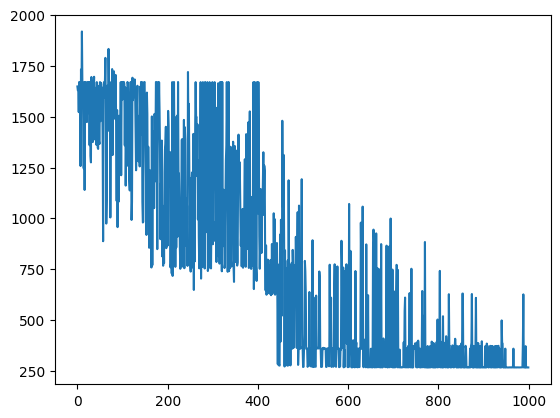

In [ ]:
# (1+1)-CMA-ESの作成
sigma = 10
mean = sigma * np.random.randn(N)
f_hist = np.empty(1000)  # この長さが最大のイテレーション数
f_hist[0] = objective(mean)
es = Cmaes(f_hist[0], mean, sigma)

# 最適化の実行
for t in range(len(f_hist)):
    w = es.ask()
    f_hist[t] = objective(w)
    es.tell(f_hist[t])
    if (t+1) % 10 == 0:
        print(t+1, np.min(f_hist[:t+1]), es.s)
    if t >= 300 and np.min(f_hist[:t+1-300]) == np.min(f_hist[:t+1]):
        # 300 イテレーション通して改善が見られない場合には終了
        f_hist = f_hist[:t+1]
        break

# 最適化途中で得られた解の目的関数値を可視化
plt.plot(f_hist)

# 1. 目的を明確にする



「より優れた方策を獲得できる方法」という表現は曖昧なので，何を持って優れていると判断するかの指標を定量的に定めることが必要です．指標は目的によって変わるものであるため，目的に沿った合理的な指標を定めることが重要です．


## 1.1 方策の評価指標


ここでは，上述の`objective`関数で評価している指標と同じく，「方策によって得られる累積報酬の90パーセンタイルの値」を方策の良さとして定義します．なお，この評価方法は強化学習の文脈では必ずしも一般的なものではありません．強化学習はあくまで累積報酬の期待値を最大化することを目的とするため，この目的のためにはあまり適さないことになります．進化計算を用いるからこそ可能な指標であることに注意してください．

さて，`objective`関数では，固定された乱数10個を用いてそれぞれ1エピソード分のインタラクションを実施し，累積報酬を計算しています．これは最適化の都合上の設計ですが，評価の観点からは適切ではありません．その理由として，以下の２つが挙げられます．

1. 10エピソード分の累積報酬（10個のサンプル）で90パーセンタイルを計算しても，その推定精度（理論上の90パーセンタイルに対する10サンプルで計算される推定値の差）は高いとは言えない．

2. 関数内で使用されている乱数系列にオーバーフィットした方策が得られており，他の乱数系列で評価した場合にはより悪い90%になる可能性がある．

そのため，評価時には最適化時よりも高い精度での90%の推定が求められます．
そのための方法としてはいくつか考えられますが，ここでは「最適化時とは異なる100エピソード分の累積報酬値を計算し，それらの90パーセンタイルを計算した結果」を評価指標とします．

In [10]:
def evaluate(policy, envname):
    return_array = np.zeros(100)
    for i in range(len(return_array)):
        history, img = rollout(envname, policy=policy, render=False)
        return_array[i] = cumulative_reward(history)
    return np.percentile(- return_array, 90), return_array

上の実行例で得られた方策を評価してみます．最適化時に得られた目的関数の値よりも高い値になってしまっていることが確認できます．

In [11]:
policy = NNPolicy(es.x, Na, Ns, K)
p90, return_array = evaluate(policy, envname)
print(p90)

NameError: name 'es' is not defined

経験分布関数も確認しておきましょう．

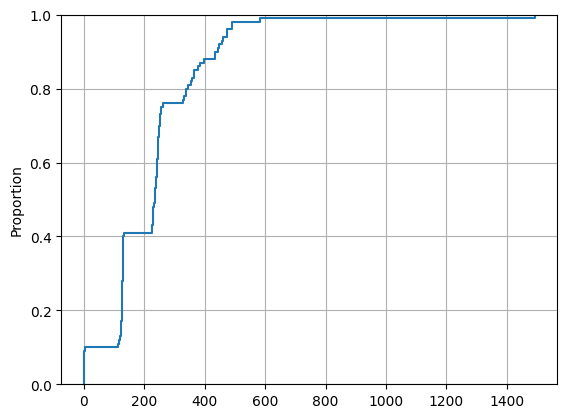

In [ ]:
fig, ax = plt.subplots()
sns.ecdfplot(data=-return_array, ax=ax)
plt.grid()

## 1.2 方法の評価



「良い方策」の指標が得られたので，「良い最適化法」の評価指標を検討します．
当然良い方策を得ることが目的ですから，より良い方策を得ることが可能な最適化法が優れているということになります．

ただし，以下の点に注意が必要です．
1. 最適化法を実行するたびに得られる解（方策）が変わる（最適化法自体の確率的な要因，初期値の確率的な要因）
2. 最適化法によって，最適化にかかるコスト（ここでは環境とのインタラクション数がボトルネックですので，これをコストと考えます）が異なる

一点目に対処するために，最低でも5回程度は同じ最適化を，乱数を変えて実行しましょう．

二点目はなかなか難しい問題です．早くある程度良い解を見つけることができる方法と，時間はかかるもののよりよい解を見つけることができる方法のどちらがよいかは，どれだけのコストを許容できるかに依存します．そのため，いくつかのアプローチが取られています．

1. 収束したとみなせるほど十分なコストをかけた後に得られる解同士の性能比較
2. 十分に良い性能と判断できる性能のしきい値に達するまでに費やしたコスト同士の比較
3. 収束曲線を描き，多元的に比較

いずれも良し悪しあります．１つ目はコストを気にせずとにかく良い解が得られるのかの評価です．２つ目は同じ性能に達するまでにかかるコストの比較なので，これが可能なのであれば概ね妥当な評価になります．ただし，十分に良い性能と判断できるしきい値の設定に依存してしまいます．３つ目は定量的な評価になりませんが，速度と性能の両者を考慮した比較が可能になります．必ずしも勝者が決まるような比較ではありませんが，方法間の性質の比較を行う際には有益です．ここでは３つ目の方法を採用することにしましょう．




# ２．実験方法の検討

評価方法が決まったので，比較実験の方法を実装していきましょう．
比較対象となるアルゴリズムは各自で実装してもらうことになります．


今回用いている`Pendulum-v1`環境では，1エピソード毎に実行されるインタラクション数が500で固定です．そのため，コストは単純にエピソード数と考えて問題ありません．また，上で定義した目的関数は一度の90パーセンタイルの計算に10エピソードを必要とします．今回の(1+1)-CMA-ESでは，1イテレーションに1度の目的関数評価を必要とするため，
(1+1)-CMA-ESの1イテレーション当たりのコストは10エピソード，となります．アルゴリズムによってこのコストが変わりますので，平等な比較になるように注意が必要です．


比較したい方法を以下のようなかたちで実装しておきます．これは上に示した(1+1)-CMA-ESにほかなりません．ただし，評価方法に合わせてログの取り方を変えています．

In [ ]:
def optimize1(maxeps=10000, logfile='./1p1cmaes.txt'):
    # (1+1)-CMA-ESの作成
    neps = 10
    sigma = 10
    mean = sigma * np.random.randn(N)
    f_hist = np.empty(maxeps // 10)  # 最適化中の目的関数値のログ
    f_hist[:] = np.nan
    f_hist[0] = objective(mean)
    es = Cmaes(f_hist[0], mean, sigma)

    # 最適化の途中で得られた解を10イテレーション（100エピソード）毎にファイルに書き出し
    with open(logfile, 'w') as f:
        f.write(str(neps) + ' ' + str(f_hist[0]) + ' ' + ' '.join(map(str, es.x)) + '\n')

    # 最適化の実行
    for t in range(1, len(f_hist)):
        w = es.ask()
        f_hist[t] = objective(w)
        neps += 10
        es.tell(f_hist[t])

        # 最適化の途中で得られた解を10イテレーション（100エピソード）毎にファイルに書き出し
        if (t+1) % 10 == 0:
            print(t+1, np.min(f_hist[:t+1]), es.s)
            with open(logfile, 'a') as f:
                f.write(str(neps) + ' ' + str(np.min(f_hist[:t+1])) + ' ' + ' '.join(map(str, es.x)) + '\n')

    return es.x

1.1，1.2節で示した方法で最適化法を評価するために，乱数を変えて最適化を5回繰り返し，その結果を保存します．保存された解を`evaluate`関数を用いて評価することで，それぞれの最適化試行の途中に得られた解を評価します．最後に，5試行分の平均と標準偏差を確認します．

In [ ]:
# 最適化実行
# ローカルで実行する場合には，複数試行の実施は並列に実施してしまうと効率的
for trial in range(1, 6):
    print("Trial ", trial)
    np.random.seed(trial * 1234)
    optimize1(logfile='./1p1cmaes_trial{}.txt'.format(trial))

Trial  1
10 1348.6844505680076 10.5540182229534
20 1344.2895269925102 10.298485624720412
30 1340.9123076722433 10.04913995049876
40 1088.0341357038612 10.298485624720406
50 955.103316691187 10.049139950498756
60 955.103316691187 9.568413812767783
70 878.9628969955784 9.3367445479538
80 878.9628969955784 8.890097654027738
90 878.9628969955784 8.46481724890612
100 754.5936902858135 8.464817248906117
110 754.5936902858135 8.059881212318905
120 754.5936902858135 7.6743163197157145
130 754.5936902858135 7.307195903214838
140 754.5936902858135 6.957637624446742
150 754.5936902858135 6.624801353939238
160 754.5936902858135 6.307887151947648
170 754.5936902858135 6.006133345877098
180 754.5936902858135 5.718814699676196
190 754.5936902858135 5.445240670802411
200 754.5936902858135 5.184753750569945
210 754.5936902858135 4.936727883891279
220 754.5936902858135 4.700566964614395
230 754.5936902858135 4.475703402839367
240 678.08477021849 4.4757034028393665
250 678.08477021849 4.261596760771003
2

In [ ]:
# 方策の評価
# 方策の評価も比較的時間がかかるので，ローカルで並列実行するとよい
hist = []
for trial in range(1, 6):
    logfile = './1p1cmaes_trial{}.txt'.format(trial)
    dat = np.loadtxt(logfile)
    p90_array = np.zeros((2, len(dat)))
    for i in range(len(dat)):
        p90_array[0, i] = dat[i, 0]
        p90_array[1, i] = evaluate(NNPolicy(dat[i, 2:], Na, Ns, K), envname)[0]
    hist.append(p90_array)

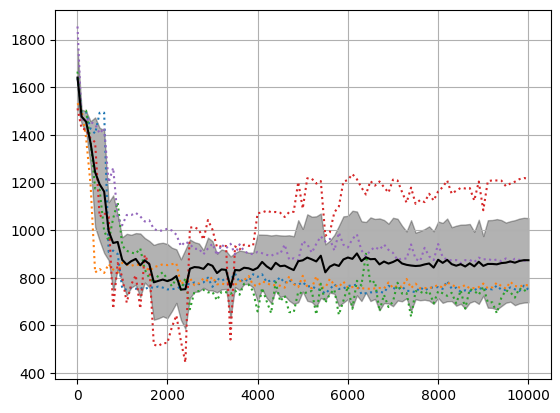

In [ ]:
# 学習曲線の可視化
import matplotlib.pyplot as plt
plt.figure()
# 各試行の結果をプロット
for i, p90_array in enumerate(hist):
    plt.plot(p90_array[0], p90_array[1], ':')
# 平均と標準偏差をプロット
p90_stacked = np.vstack([p90_array[1] for p90_array in hist])
p90_avg = np.mean(p90_stacked, axis=0)
p90_std = np.std(p90_stacked, axis=0)
plt.plot(hist[0][0], p90_avg, '-', color='k')
plt.fill_between(hist[0][0], p90_avg - p90_std, p90_avg + p90_std, alpha=0.3, color='k')
plt.grid()
# 図の保存
plt.savefig('1p1cmaes.eps')

方法間の比較にはこの平均と標準偏差を主に見ていくことになります．各試行での結果もここでは確認していますが，これは平均や標準偏差が5試行を十分に代表していると考えられるかを確認するためです．試行毎にあまりにも大きな偏りがある場合，平均をみることが適切とは言えないので，一度は確認しておくことが重要です．問題なければみやすさのために比較の際にはプロットしないようにしましょう．

２つ以上の結果を比較したい場合には，一つの図にして保存しましょう．
比較をしたいのに複数の図にまたがっていると比較が難しくなります．
また，データを可視化して保存する場合には，ベクトル形式の図（epsなど）で保存しましょう．ビットマップ形式で保存するとデータの情報が欠落してしまうため，科学技術文書では望ましくありません．

# 3 アルゴリズムの提案と実験的比較

実験の準備は整ったので，あとは(1+1)-CMA-ESよりも優れた方法を検討し，実装しましょう．方法といっても，完全に新しい方法を設計する必要はありません．(1+1)-CMA-ESをベースにして，一部を変更する，といった方法で結構です．抜本的に異なる方法を検討するよりも，一部のみが異なる方法を比較したほうが，どういった工夫がどのように影響するのかを理解しやすいためです（研究の基本です）．

結果的に優れているとみなせない方法になっても構いません．ただ，時間の許す限り，試行錯誤してみてください．設計した方法を`optimize1`をまねて`optimize2`などとして実行できる関数として実装しましょう．その後，上の方法に従って比較しましょう．

以下に改善案の例を挙げておきます．

* 最適化時の目的関数を90パーセンタイルから95パーセンタイルに変更する
  - 理由と期待される効果：最適化時に得られている目的関数値と比較して評価時の値が著しく悪いのは，最適化時に用いている乱数系列にオーバーフィットしてしまっているからであると考えられる．ただ，評価時の経験分布関数を見ると，完全に最適化時の乱数系列だけにオーバーフィットしているのではなく，望ましい性能を示す割合が90％よりも低くなってしまっている．そこで，最適化時の目的関数を90パーセンタイルでなく95パーセンタイルや99パーセンタイルなどとしておくことで，この割合が下がったとしても90パーセント以上の試行で優れた性能を示す方策を獲得できるのではないか，と期待される．

* 最適化時の目的関数評価におけるエピソード数を100に変更する
  - 理由と期待される効果：上述のように，オーバーフィットにより，最適化している目的関数の最小化が評価時の真の目的に対応していない点に改善の余地がある．目的関数はあくまで真の目的の推定値であるから，この推定精度をあげることができれば，乖離を抑えることが可能であると考えられる．目的関数計算時のエピソード数を増加させることで，これは実現可能であると考えられる．しかし，一度の目的関数評価毎に費やすエピソード数が増加するため，最終性能は改善するかもしれないが，コストは多くかかるようになると予想される．

上のように，原因となりそうな部分に着目し，これを改善することを考えてみてください．また，その変更による影響を予め予想しておくことが重要です．実験は，この**予想（仮説）が正しいかどうかを検証するプロセス**です．



In [ ]:
def optimize2(maxeps=100000, logfile='./1p1cmaes.txt',nval=100):
    # (1+1)-CMA-ESの作成
    neps = nval
    sigma = 10
    mean = sigma * np.random.randn(N)
    f_hist = np.empty(maxeps // neps)  # 最適化中の目的関数値のログ
    f_hist[:] = np.nan
    f_hist[0] = objective(mean)
    es = Cmaes(f_hist[0], mean, sigma)

    with open(logfile, 'w') as f:
        f.write(str(neps) + ' ' + str(f_hist[0]) + ' ' + ' '.join(map(str, es.x)) + '\n')

    # 最適化の実行
    for t in range(1, len(f_hist)):
        w = es.ask()
        f_hist[t] = objective(w,nval)
        neps += nval
        es.tell(f_hist[t])

        # 最適化の途中で得られた解を10イテレーション（10×nvalエピソード）毎にファイルに書き出し
        if (t+1) % 10 == 0:
            print(t+1, np.min(f_hist[:t+1]), es.s)
            with open(logfile, 'a') as f:
                f.write(str(neps) + ' ' + str(np.min(f_hist[:t+1])) + ' ' + ' '.join(map(str, es.x)) + '\n')

    return es.x

In [ ]:
for trial in range(1, 6):
    print("Trial ", trial)
    np.random.seed(trial * 1234)
    optimize2(logfile='./1p1cmaes_trialnval_100{}.txt'.format(trial))

Trial  1
10 1492.9134583713565 10.298485624720414
20 1398.4727623348688 10.298485624720412
30 1398.4727623348688 9.805831403241083
40 1108.6234339154341 10.04913995049876
50 1079.5135162679894 9.805831403241081
60 1079.5135162679894 9.336744547953806
70 1079.5135162679894 8.890097654027745
80 1079.5135162679894 8.464817248906128
90 1079.5135162679894 8.059881212318913
100 996.6982969339275 7.864736354301343
110 995.0438283493299 7.6743163197157225
120 756.0680783936072 7.488506711715064
130 756.0680783936072 7.130274969831863
140 756.0680783936072 6.789180153350879
150 756.0680783936072 6.464402473911938
160 756.0680783936072 6.155161359813612
170 756.0680783936072 5.860713579984726
180 756.0680783936072 5.580351457700451
190 630.1255428071215 5.4452406708024155
200 630.1255428071215 5.184753750569949
210 630.1255428071215 4.936727883891282
220 630.1255428071215 4.7005669646143975
230 630.1255428071215 4.47570340283937
240 630.1255428071215 4.261596760771006
250 630.1255428071215 4.057

In [ ]:
hist = []
for trial in range(1, 6):
    logfile = './1p1cmaes_trianval_100{}.txt'.format(trial)
    dat = np.loadtxt(logfile)
    p90_array = np.zeros((2, len(dat)))
    for i in range(len(dat)):
        p90_array[0, i] = dat[i, 0]
        p90_array[1, i] = evaluate(NNPolicy(dat[i, 2:], Na, Ns, K), envname)[0]
    hist.append(p90_array)

In [ ]:
# 学習曲線の可視化
import matplotlib.pyplot as plt
plt.figure()
# 各試行の結果をプロット
for i, p90_array in enumerate(hist):
    plt.plot(p90_array[0], p90_array[1], ':')
# 平均と標準偏差をプロット
p90_stacked = np.vstack([p90_array[1] for p90_array in hist])
p90_avg = np.mean(p90_stacked, axis=0)
p90_std = np.std(p90_stacked, axis=0)
plt.plot(hist[0][0], p90_avg, '-', color='k')
plt.fill_between(hist[0][0], p90_avg - p90_std, p90_avg + p90_std, alpha=0.3, color='k')
plt.grid()
# 図の保存
plt.savefig('1p1cmaesnval_100.eps')

In [32]:
def optimize3(maxeps=10000, logfile='./1p1cmaes.txt',nval=100):
    # (1+1)-CMA-ESの作成
    neps = nval
    sigma = 10
    mean = sigma * np.random.randn(N)
    f_hist = np.empty(maxeps // neps)  # 最適化中の目的関数値のログ
    f_hist[:] = np.nan
    f_hist[0] = objective(mean)
    es = Cmaes(f_hist[0], mean, sigma)

    with open(logfile, 'w') as f:
        f.write(str(neps) + ' ' + str(f_hist[0]) + ' ' + ' '.join(map(str, es.x)) + '\n')

    # 最適化の実行
    for t in range(1, len(f_hist)):
        w = es.ask()
        f_hist[t] = objective(w,nval)
        neps += nval
        es.tell(f_hist[t])

        # 最適化の途中で得られた解を10イテレーション（10×nvalエピソード）毎にファイルに書き出し
        if (t+1) % 10 == 0:
            print(t+1, np.min(f_hist[:t+1]), es.s)
            with open(logfile, 'a') as f:
                f.write(str(neps) + ' ' + str(np.min(f_hist[:t+1])) + ' ' + ' '.join(map(str, es.x)) + '\n')

    return es.x

In [33]:
for trial in range(1, 6):
    print("Trial ", trial)
    np.random.seed(trial * 1234)
    optimize3(logfile='./1p1cmaes_trialnval_10{}.txt'.format(trial))

Trial  1
10 1492.9134583713565 10.298485624720414
20 1398.4727623348688 10.298485624720412
30 1398.4727623348688 9.805831403241083
40 1108.6234339154341 10.04913995049876
50 1079.5135162679894 9.805831403241081
60 1079.5135162679894 9.336744547953806
70 1079.5135162679894 8.890097654027745
80 1079.5135162679894 8.464817248906128
90 1079.5135162679894 8.059881212318913
100 996.6982969339275 7.864736354301343
Trial  2
10 1502.934490441747 10.049139950498766
20 1389.5261443394124 9.805831403241086
30 1191.4745299702208 9.805831403241083
40 845.9297639990003 9.80583140324108
50 845.9297639990003 9.336744547953804
60 845.9297639990003 8.890097654027743
70 845.9297639990003 8.464817248906126
80 845.9297639990003 8.059881212318912
90 845.9297639990003 7.674316319715721
100 845.9297639990003 7.307195903214844
Trial  3
10 1497.268986698399 9.805831403241086
20 1411.816980646966 9.805831403241084
30 1317.3665133623354 9.56841381276779
40 1271.076269801274 9.336744547953806
50 1271.076269801274 8

In [34]:
hist = []
for trial in range(1, 6):
    logfile = './1p1cmaes_trialnval_10{}.txt'.format(trial)
    dat = np.loadtxt(logfile)
    p90_array = np.zeros((2, len(dat)))
    for i in range(len(dat)):
        p90_array[0, i] = dat[i, 0]
        p90_array[1, i] = evaluate(NNPolicy(dat[i, 2:], Na, Ns, K), envname)[0]
    hist.append(p90_array)

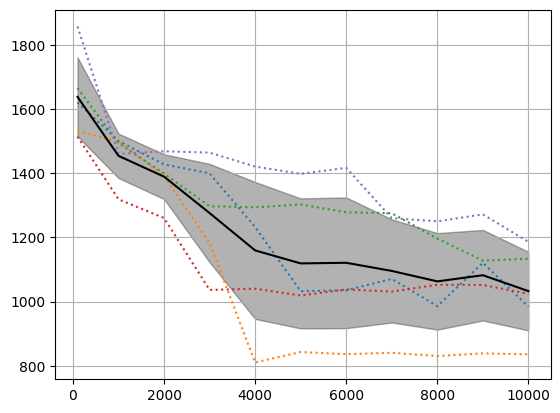

In [35]:
# 学習曲線の可視化
import matplotlib.pyplot as plt
plt.figure()
# 各試行の結果をプロット
for i, p90_array in enumerate(hist):
    plt.plot(p90_array[0], p90_array[1], ':')
# 平均と標準偏差をプロット
p90_stacked = np.vstack([p90_array[1] for p90_array in hist])
p90_avg = np.mean(p90_stacked, axis=0)
p90_std = np.std(p90_stacked, axis=0)
plt.plot(hist[0][0], p90_avg, '-', color='k')
plt.fill_between(hist[0][0], p90_avg - p90_std, p90_avg + p90_std, alpha=0.3, color='k')
plt.grid()
# 図の保存
plt.savefig('1p1cmaesnval_10.eps')

In [28]:
def optimize4(maxeps=10000, logfile='./1p1cmaes_inc.txt', nval_min=5, nval_max=20):
    # (1+1)-CMA-ESの作成
    sigma = 10
    mean = sigma * np.random.randn(N)

    nval = nval_min
    neps = nval
    f0 = objective(mean, nval)
    f_hist = [f0]
    nval_hist = [nval]
    es = Cmaes(f0, mean, sigma)

    with open(logfile, 'w') as f:
        f.write(str(neps) + ' ' + str(f0) + ' ' + ' '.join(map(str, es.x)) + '\n')

    # 最適化の実行（総エピソード数がmaxepsに達するまで）
    t = 0
    while neps < maxeps:
        t += 1
        # 消費済みエピソードの割合に応じてnvalを線形に増やす
        progress = neps / maxeps
        nval = round(nval_min + (nval_max - nval_min) * progress)
        nval = min(nval, maxeps - neps)  # 予算を超えないように調整

        w = es.ask()
        f_t = objective(w, nval)
        neps += nval
        es.tell(f_t)

        f_hist.append(f_t)
        nval_hist.append(nval)

        # 10イテレーション毎にファイルに書き出し
        if (t + 1) % 10 == 0:
            print(t + 1, neps, nval, np.min(f_hist), es.s)
            with open(logfile, 'a') as f:
                f.write(str(neps) + ' ' + str(np.min(f_hist)) + ' ' + ' '.join(map(str, es.x)) + '\n')

    # 最後の状態も書き出し
    with open(logfile, 'a') as f:
        f.write(str(neps) + ' ' + str(np.min(f_hist)) + ' ' + ' '.join(map(str, es.x)) + '\n')

    return es.x, np.array(f_hist), np.array(nval_hist)

In [29]:
for trial in range(1, 6):
    print("Trial ", trial)
    np.random.seed(trial * 1234)
    optimize4(logfile='./1p1cmaes_trialnval_inc{}.txt'.format(trial))

Trial  1
10 50 5 1498.5803671225447 10.049139950498764
20 100 5 1439.870936867186 10.049139950498763
30 150 5 1376.8453272459244 10.04913995049876
40 200 5 1291.5370397350339 9.80583140324108
50 250 5 1291.5370397350339 9.336744547953804
60 300 5 1291.5370397350339 8.890097654027743
70 353 6 1291.5370397350339 8.464817248906126
80 413 6 1040.4285293868472 8.259868129103001
90 473 6 853.7269008407552 8.059881212318908
100 533 6 465.87469467089403 7.864736354301336
110 593 6 465.87469467089403 7.488506711715058
120 653 6 465.87469467089403 7.130274969831857
130 713 6 465.87469467089403 6.789180153350872
140 773 6 465.87469467089403 6.4644024739119335
150 833 6 465.87469467089403 6.155161359813608
160 893 6 378.72222757838716 6.006133345877098
170 953 6 378.72222757838716 5.718814699676196
180 1015 7 378.72222757838716 5.445240670802411
190 1085 7 378.72222757838716 5.184753750569945
200 1155 7 378.72222757838716 4.936727883891279
210 1225 7 378.72222757838716 4.700566964614395
220 1295 7

In [36]:
hist = []
for trial in range(1, 6):
    logfile = './1p1cmaes_trialnval_inc{}.txt'.format(trial)
    dat = np.loadtxt(logfile)
    p90_array = np.zeros((2, len(dat)))
    for i in range(len(dat)):
        p90_array[0, i] = dat[i, 0]
        p90_array[1, i] = evaluate(NNPolicy(dat[i, 2:], Na, Ns, K), envname)[0]
    hist.append(p90_array)

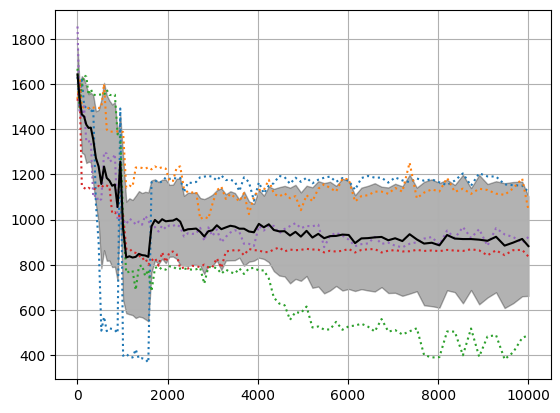

In [37]:
import matplotlib.pyplot as plt
plt.figure()
# 各試行の結果をプロット
for i, p90_array in enumerate(hist):
    plt.plot(p90_array[0], p90_array[1], ':')
# 平均と標準偏差をプロット
p90_stacked = np.vstack([p90_array[1] for p90_array in hist])
p90_avg = np.mean(p90_stacked, axis=0)
p90_std = np.std(p90_stacked, axis=0)
plt.plot(hist[0][0], p90_avg, '-', color='k')
plt.fill_between(hist[0][0], p90_avg - p90_std, p90_avg + p90_std, alpha=0.3, color='k')
plt.grid()
# 図の保存
plt.savefig('1p1cmaesnval_inc.eps')

In [41]:
def optimize5(maxeps=10000, logfile='./1p1cmaes_inc_reeval.txt',
              nval_min=10, nval_max=20):
    # (1+1)-CMA-ESの作成
    sigma = 10
    mean = sigma * np.random.randn(N)

    nval = nval_min
    neps = nval
    f0 = objective(mean, nval)
    f_hist = [f0]
    nval_hist = [nval]
    es = Cmaes(f0, mean, sigma)
    parent_f = f0   # 今の親の評価値を自分でも追跡しておく

    def set_parent_f(es, old, new):
        # fhistの中で今の親の値が入っている位置（末尾 or 先頭）を書き換える
        fh = es.fhist
        if fh[-1] == old:
            fh[-1] = new
        elif fh[0] == old:
            fh[0] = new
        else:
            raise RuntimeError(f'fhist内に親の評価値が見つかりません: {fh}')

    with open(logfile, 'w') as f:
        f.write(str(neps) + ' ' + str(f0) + ' ' + ' '.join(map(str, es.x)) + '\n')

    # 最適化の実行（総エピソード数がmaxepsに達するまで）
    t = 0
    prev_nval = nval
    n_reeval = 0
    while neps < maxeps:
        t += 1
        # 消費済みエピソードの割合に応じてnvalを線形に増やす
        progress = neps / maxeps
        nval = round(nval_min + (nval_max - nval_min) * progress)
        nval = min(nval, maxeps - neps)

        # nvalが増えたら、親を新しいnvalで評価し直して比較基準を更新
        if nval > prev_nval and neps + 2 * nval <= maxeps:
            new_f = objective(es.x, nval)
            set_parent_f(es, parent_f, new_f)
            parent_f = new_f
            neps += nval
            n_reeval += 1
            prev_nval = nval

        if neps >= maxeps:
            break
        nval = min(nval, maxeps - neps)

        x_before = es.x.copy()
        w = es.ask()
        f_t = objective(w, nval)
        neps += nval
        es.tell(f_t)

        # 親が入れ替わったら（xが変化したら）親の評価値を更新
        if not np.array_equal(es.x, x_before):
            parent_f = f_t

        f_hist.append(f_t)
        nval_hist.append(nval)

        # 10イテレーション毎にファイルに書き出し
        if (t + 1) % 10 == 0:
            print(t + 1, neps, nval, np.min(f_hist), es.s)
            with open(logfile, 'a') as f:
                f.write(str(neps) + ' ' + str(np.min(f_hist)) + ' ' + ' '.join(map(str, es.x)) + '\n')

    # 最後の状態も書き出し
    with open(logfile, 'a') as f:
        f.write(str(neps) + ' ' + str(np.min(f_hist)) + ' ' + ' '.join(map(str, es.x)) + '\n')

    print('再評価回数:', n_reeval, ' 総エピソード数:', neps)
    return es.x, np.array(f_hist), np.array(nval_hist)

In [42]:
for trial in range(1, 6):
    print("Trial ", trial)
    np.random.seed(trial * 1234)
    optimize5(logfile='./1p1cmaes_trialnval_inc2{}.txt'.format(trial))

Trial  1
10 100 10 1348.6844505680076 10.5540182229534
20 200 10 1344.2895269925102 10.298485624720412
30 300 10 1340.9123076722433 10.04913995049876
40 400 10 1088.0341357038612 10.298485624720406
50 500 10 955.103316691187 10.049139950498756
60 620 11 955.103316691187 9.568413812767783
70 730 11 863.080149879793 9.3367445479538
80 840 11 863.080149879793 8.890097654027738
90 950 11 863.080149879793 8.46481724890612
100 1060 11 753.083304117888 8.464817248906117
110 1170 11 753.083304117888 8.059881212318905
120 1280 11 753.083304117888 7.6743163197157145
130 1390 11 753.083304117888 7.307195903214838
140 1500 11 753.083304117888 6.957637624446742
150 1632 12 753.083304117888 6.624801353939238
160 1752 12 753.083304117888 6.307887151947648
170 1872 12 753.083304117888 6.006133345877098
180 1992 12 753.083304117888 5.718814699676196
190 2112 12 753.083304117888 5.445240670802411
200 2232 12 753.083304117888 5.184753750569945
210 2352 12 753.083304117888 4.936727883891279
220 2472 12 75

In [44]:
hist = []
for trial in range(1, 6):
    logfile = './1p1cmaes_trialnval_inc2{}.txt'.format(trial)
    dat = np.loadtxt(logfile)
    p90_array = np.zeros((2, len(dat)))
    for i in range(len(dat)):
        p90_array[0, i] = dat[i, 0]
        p90_array[1, i] = evaluate(NNPolicy(dat[i, 2:], Na, Ns, K), envname)[0]
    hist.append(p90_array)

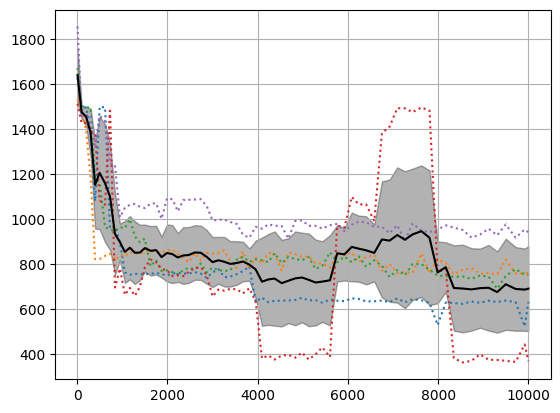

In [47]:
import matplotlib.pyplot as plt
plt.figure()
# 各試行の結果をプロット
for i, p90_array in enumerate(hist):
    plt.plot(p90_array[0], p90_array[1], ':')
# 平均と標準偏差をプロット
p90_stacked = np.vstack([p90_array[1] for p90_array in hist])
p90_avg = np.mean(p90_stacked, axis=0)
p90_std = np.std(p90_stacked, axis=0)
plt.plot(hist[0][0], p90_avg, '-', color='k')
plt.fill_between(hist[0][0], p90_avg - p90_std, p90_avg + p90_std, alpha=0.3, color='k')
plt.grid()
# 図の保存
plt.savefig('1p1cmaesnval_inc2.eps')

=== 存在している .eps ファイル一覧 ===
1p1cmaesnval_10.eps
1p1cmaesnval_inc.eps

❌ 1p1cmaesnval_in2.eps は見つかりませんでした。書き出し時のファイル名を確認してください。


# 4. レポートの提出

レポートは次のような章立てで，LaTeXなどを用いて作成してください．

1. 実験の目的，検証したい仮説．実験は仮説検証のプロセスですから，必ず目的から書きましょう．目的があって初めて適切な実験設定があります．

2. 提案するアルゴリズム

  1. 提案法のアイディア，提案の理由と期待される効果（上の記述を参考にしてください）

  2. 提案法の具体的な方法．(1+1)-CMA-ESをベースとした方法であれば，アルゴリズムの全体の説明がなくとも，変更点が明確であれば構いませんが，他の人が見てその方法を実装するのに必要な情報を全て記載しましょう．研究論文では再現性といって，重要な評価項目となります．

3. 実験方法．この項目も他の人が再現できるように必要な情報を全て記載しましょう．

  1. 評価指標の説明
  2. 実験設定や具体的な実験方法．使用した環境（'Pendulum-v1'）であること，使用した方策，など，その実験を再現するために必要な情報を記載しましょう．
  
4. 実験結果．結果として表示する図の読み取り方，図から読み取れること，これが予想と一致しているのかについての結論を述べましょう．

5. 考察．今回の結論が得られた原因についての考察を記述しましょう．良い考察は，**単なる予想ではなく，それを裏付ける結果とともに示されているもの**になります．
例えば方法Aと方法Bを比較した場合に何らかの違いが性能差として見られたとします．この差は，方法AとBの間のアルゴリズム上の差によって，例えば目的関数の推定精度が変わり，その結果として性能に差が生じていると考えられます．性能の差を見ているだけでは，アルゴリズムの差→推定精度の差，という部分は予想に過ぎないことになります．そこで，性能差だけでなく，推定精度に差が生じているのか，を実際にデータをとって確認することにより，推論に根拠を与えていきます．

6. まとめ．今回の実験を振り返り，得られた知見をまとめましょう．また，現在の実験では確認しきれていないこと，検証の弱いところ，考えられる改善点，などについてまとめましょう．



